<a href="https://colab.research.google.com/github/AnjanaVP231/ML/blob/main/lab4_KNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving KNN_Dataset.xlsx - KNN_Dataset.csv to KNN_Dataset.xlsx - KNN_Dataset (1).csv
  Phone_ID  RAM_GB  Storage_GB  Battery_mAh  Camera_MP   Category
0      P01       4          41         4763         63     Budget
1      P02       4          49         4928         48     Budget
2      P03       7         119         4786         62  Mid-Range
3      P04      13         261         4656        123    Premium
4      P05       3          57         4335         41     Budget
5      P06      13         285         4746         98    Premium
6      P07       9         123         4485         50  Mid-Range
7      P08      12         288         4413         95    Premium
8      P09       5          65         4601         59     Budget
9      P10      11         250         4288        100    Premium

Input Features:
['RAM_GB', 'Storage_GB', 'Battery_mAh', 'Camera_MP']

Target Variable:
Category


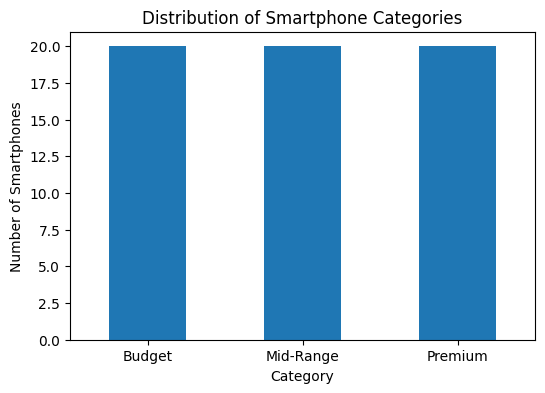


Numerical Features:
['RAM_GB', 'Storage_GB', 'Battery_mAh', 'Camera_MP']

Distances:
   Phone_ID   Category    Distance
0       P01     Budget  252.806250
1       P02     Budget  106.925208
2       P03  Mid-Range  214.527388
3       P04    Premium  376.035903
4       P05     Budget  668.846769
5       P06    Premium  302.519421
6       P07  Mid-Range  515.033009
7       P08    Premium  610.106548
8       P09     Budget  404.044552
9       P10    Premium  724.122227
10      P11    Premium  215.538860
11      P12    Premium  240.894168
12      P13  Mid-Range  512.080072
13      P14     Budget  338.474519
14      P15    Premium  175.579042
15      P16     Budget  948.576302
16      P17     Budget  296.048982
17      P18     Budget  322.194041
18      P19    Premium  558.393231
19      P20     Budget  210.900450
20      P21    Premium  657.597901
21      P22     Budget  287.579554
22      P23  Mid-Range  701.394326
23      P24    Premium  483.204925
24      P25  Mid-Range  130.560331
25  

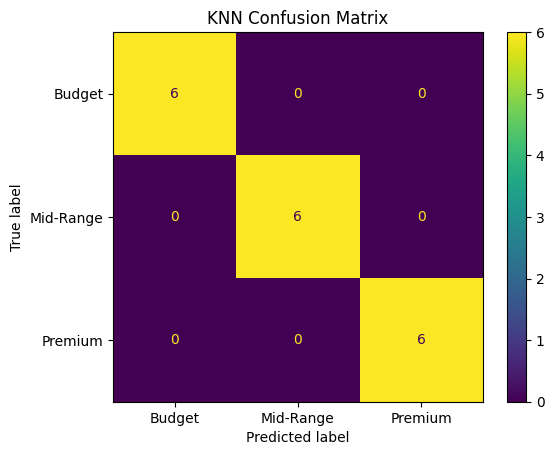


Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0

Classes:
['Budget' 'Mid-Range' 'Premium']


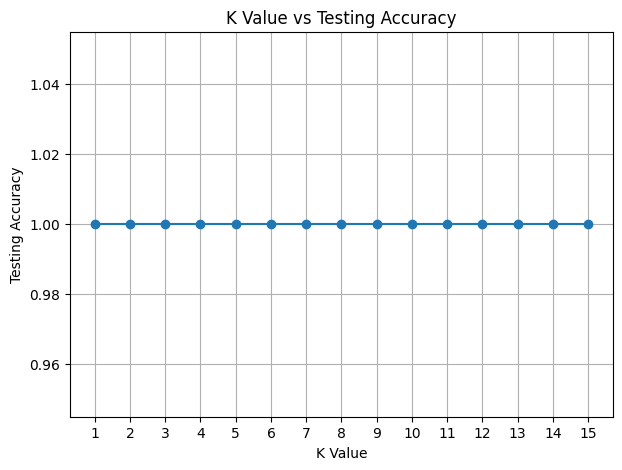


Suitable K:
1

Small K vs Larger K Predictions:
       Actual Small_K_Prediction Large_K_Prediction
0     Premium            Premium            Premium
1   Mid-Range          Mid-Range          Mid-Range
2      Budget             Budget             Budget
3      Budget             Budget             Budget
4     Premium            Premium            Premium
5     Premium            Premium            Premium
6     Premium            Premium            Premium
7      Budget             Budget             Budget
8   Mid-Range          Mid-Range          Mid-Range
9   Mid-Range          Mid-Range          Mid-Range
10  Mid-Range          Mid-Range          Mid-Range
11     Budget             Budget             Budget
12  Mid-Range          Mid-Range          Mid-Range
13     Budget             Budget             Budget
14    Premium            Premium            Premium
15     Budget             Budget             Budget
16  Mid-Range          Mid-Range          Mid-Range
17    Premium  

In [ ]:
# ============================================================
# K-NEAREST NEIGHBORS (KNN) CLASSIFICATION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ============================================================
# TASK 1: LOAD AND UNDERSTAND THE DATASET
# ============================================================

uploaded = files.upload()

file_name = list(uploaded.keys())[0]
df = pd.read_csv(file_name)

print(df.head(10))

X = df[['RAM_GB', 'Storage_GB', 'Battery_mAh', 'Camera_MP']]
y = df['Category']

print("\nInput Features:")
print(X.columns.tolist())

print("\nTarget Variable:")
print(y.name)

# Distribution of Category classes
plt.figure(figsize=(6, 4))
df['Category'].value_counts().plot(kind='bar')
plt.xlabel("Category")
plt.ylabel("Number of Smartphones")
plt.title("Distribution of Smartphone Categories")
plt.xticks(rotation=0)
plt.show()

# Numerical features
print("\nNumerical Features:")
print(X.columns.tolist())


# ============================================================
# TASK 2: DISTANCE CALCULATION AND NEAREST NEIGHBORS
# ============================================================

# New smartphone record
new_phone = np.array([6, 128, 5000, 50])

# Calculate Euclidean distances
distances = np.sqrt(
    np.sum((X.values - new_phone) ** 2, axis=1)
)

distance_df = df[['Phone_ID', 'Category']].copy()
distance_df['Distance'] = distances

print("\nDistances:")
print(distance_df)

# Sort by distance
sorted_distances = distance_df.sort_values(by='Distance')

# Select K nearest neighbors
K = 5
nearest_neighbors = sorted_distances.head(K)

print("\nK Nearest Neighbors:")
print(nearest_neighbors)

# Majority voting
prediction = nearest_neighbors['Category'].mode()[0]

print("\nPredicted Category:")
print(prediction)


# ============================================================
# TASK 3: FEATURE SCALING AND KNN WORKING
# ============================================================

scaler_manual = StandardScaler()

X_scaled = scaler_manual.fit_transform(X)

new_phone_df = pd.DataFrame(
    [new_phone],
    columns=['RAM_GB', 'Storage_GB', 'Battery_mAh', 'Camera_MP']
)

new_phone_scaled = scaler_manual.transform(new_phone_df)[0]

# Distances after scaling
scaled_distances = np.sqrt(
    np.sum((X_scaled - new_phone_scaled) ** 2, axis=1)
)

scaled_distance_df = df[['Phone_ID', 'Category']].copy()
scaled_distance_df['Scaled_Distance'] = scaled_distances

scaled_sorted = scaled_distance_df.sort_values(
    by='Scaled_Distance'
)

scaled_nearest_neighbors = scaled_sorted.head(K)

print("\nNearest Neighbors Before Scaling:")
print(nearest_neighbors)

print("\nNearest Neighbors After Scaling:")
print(scaled_nearest_neighbors)

# Complete KNN working
scaled_prediction = scaled_nearest_neighbors['Category'].mode()[0]

print("\nKNN Working:")
print("Input:", new_phone)
print("Scaled Input:", new_phone_scaled)
print("Nearest Neighbors:")
print(scaled_nearest_neighbors)
print("Prediction:", scaled_prediction)


# ============================================================
# TASK 4: IMPLEMENT KNN USING SCIKIT-LEARN
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

K = 5

knn = KNeighborsClassifier(n_neighbors=K)

knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=knn.classes_)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=knn.classes_
)

disp.plot()
plt.title("KNN Confusion Matrix")
plt.show()

# Evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average='weighted',
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average='weighted',
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average='weighted',
    zero_division=0
)

print("\nAccuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

print("\nClasses:")
print(knn.classes_)


# ============================================================
# TASK 5: SELECTING THE VALUE OF K
# ============================================================

k_values = range(1, 16)
k_accuracies = []

for k in k_values:

    model = KNeighborsClassifier(n_neighbors=k)

    model.fit(X_train_scaled, y_train)

    prediction_k = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, prediction_k)

    k_accuracies.append(acc)

# K vs Testing Accuracy
plt.figure(figsize=(7, 5))
plt.plot(k_values, k_accuracies, marker='o')
plt.xlabel("K Value")
plt.ylabel("Testing Accuracy")
plt.title("K Value vs Testing Accuracy")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

# Suitable K
best_k = k_values[np.argmax(k_accuracies)]

print("\nSuitable K:")
print(best_k)

# Small K prediction
small_k = 1

small_k_model = KNeighborsClassifier(n_neighbors=small_k)
small_k_model.fit(X_train_scaled, y_train)

small_k_prediction = small_k_model.predict(X_test_scaled)

# Larger K prediction
large_k = 11

large_k_model = KNeighborsClassifier(n_neighbors=large_k)
large_k_model.fit(X_train_scaled, y_train)

large_k_prediction = large_k_model.predict(X_test_scaled)

comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Small_K_Prediction': small_k_prediction,
    'Large_K_Prediction': large_k_prediction
})

print("\nSmall K vs Larger K Predictions:")
print(comparison)


# ============================================================
# TASK 6: NEW PREDICTION AND MODEL UNDERSTANDING
# ============================================================

new_phones = pd.DataFrame({
    'RAM_GB': [4, 8, 12],
    'Storage_GB': [64, 128, 256],
    'Battery_mAh': [4000, 5000, 5000],
    'Camera_MP': [16, 50, 108]
})

# Use trained KNN model
final_knn = KNeighborsClassifier(n_neighbors=K)
final_knn.fit(X_train_scaled, y_train)

new_phones_scaled = scaler.transform(new_phones)

new_predictions = final_knn.predict(new_phones_scaled)

for i in range(len(new_phones)):

    distances_new, indices_new = final_knn.kneighbors(
        new_phones_scaled[i].reshape(1, -1)
    )

    neighbor_indices = indices_new[0]
    neighbor_distances = distances_new[0]

    neighbor_table = df.iloc[
        X_train.index[neighbor_indices]
    ][['Phone_ID', 'Category']].copy()

    neighbor_table['Distance'] = neighbor_distances

    print("\nNew Smartphone", i + 1)
    print(new_phones.iloc[i])
    print("\nNearest Neighbors:")
    print(neighbor_table)
    print("\nPredicted Category:")
    print(new_predictions[i])